# Homework 10


**Concepts covered:**

pandas `DataFrame`s: initialization,  descriptive statistics, line plot, scatter plot, histogram, column-wise operations, row-wise operations.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.

**Sample Output:**

For each problem description, a sample output has been included to show what the expected output should be.
Some functions have test cases provided for you to test with, so no sample output has been included for those.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [1]:
"shared imports for csv files"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.close("all")

def read_week_10_csv(file_name):
    "function for read_week_10_csv"
    url = "https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-10/" + file_name
    try:
        return pd.read_csv(url)
    except Exception:
        return pd.read_csv(file_name)

df_stock_prices = read_week_10_csv("SPY.csv")
df_stock_prices.index = pd.to_datetime(df_stock_prices["date"], unit='s')

df_weather = read_week_10_csv("02215_weather.csv")
df_weather.index = pd.to_datetime(df_weather["datetime"], format="%m/%d/%y")


df_econ_data = read_week_10_csv("annual_data.csv")
df_econ_data.index = df_econ_data["Year"]



**Note: This will be partially manually graded, so please allow some time before getting your full grade.**

**Review Problem 1**

**Concept:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that produces a spiral/cyclone pattern.

* Generate radius values that gradually increase
* Generate angle values that rotate around the origin
* Compute:
  * x = radius × cos(angle)
  * y = radius × sin(angle)
* Plot the points using plt.scatter()
* Add a title

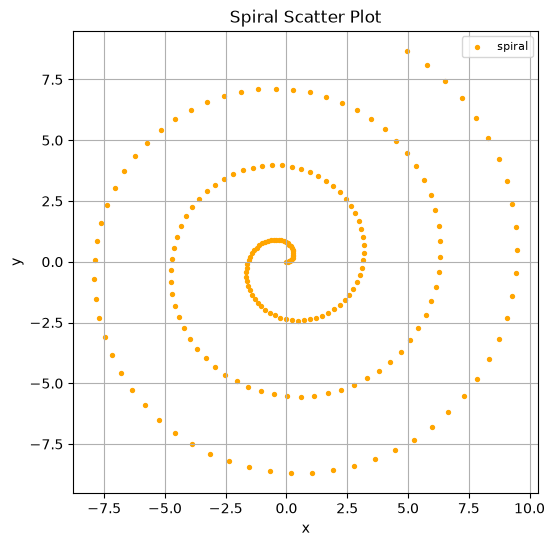

In [2]:
# Your Solution
import matplotlib.pyplot as plt
import numpy as np
"""Plots a spiral scatter plot using cos and sin angles."""
angle = np.arange(0, 20, 0.1)                 
radius = np.linspace(0, 10, len(angle))  

x_spiral = radius * np.cos(angle)            
y_spiral = radius * np.sin(angle)    

x = np.arange(0, 20, 0.1)
y = np.cos(x) 

# Create the plot
plt.figure(figsize=(6, 6))
plt.scatter(x_spiral, y_spiral, s=8, color='orange', label='spiral')

# labels and a title
plt.title('Spiral Scatter Plot')
plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal')
plt.grid(True)
plt.legend(loc='upper right', fontsize=8)


**Review Problem 2**

**Concept:** *reading CSV data, matplotlib, line graph*

**Task:**

Write a function `read_and_plot_column(filename, column_name)` that:
* Opens a CSV file (do **not** use pandas)
* Extracts the values from the specified column
* Casts all values to `float`
* Plots the values using `plt.plot()`
* Adds a title
* Displays the plot

In [3]:
# Your Solution
def split_line(line):
    """Splits one line of a file into fields, keeping commas inside quotes."""
    fields = []
    current = ""
    in_quotes = False
    for char in line:
        if char == '"':
            in_quotes = not in_quotes
        elif char == "," and not in_quotes:
            fields.append(current)
            current = ""
        else:
            current += char
    fields.append(current)
    return fields

def read_and_plot_column(filename, column_name):
    """Plots a line graph of a CSV column."""
    values = []

    with open(filename, encoding="utf-8-sig") as f:
        # first line is the header; find the position of the column
        header = split_line(f.readline().strip())
        column_position = header.index(column_name)

        for line in f:
            fields = split_line(line.strip())
            if len(fields) > column_position and fields[column_position] != "":
                values.append(float(fields[column_position]))

    plt.figure(figsize=(12, 5))
    plt.plot(values, linewidth=1.2, color='red', label=column_name)

    plt.title(f"{column_name} from {filename}", fontsize=14, pad=12)
    plt.xlabel("Day")
    plt.ylabel(column_name)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()


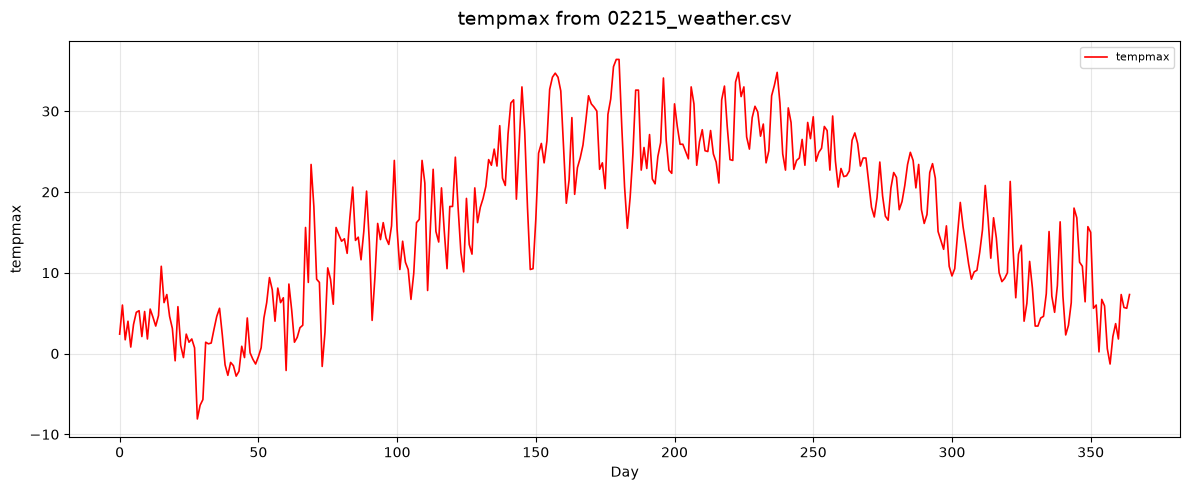

In [4]:
# test case:
read_and_plot_column("02215_weather.csv", "tempmax")


**Problem 3**

**Concept:** *Examining Data*


**Task:**

Using `df_weather`:
* Print the first 5 rows
* Print the last 5 rows

**Important:**

Store your results in the variables below and print them. The autograder will check for these variables.
* `df_weather_head`
* `df_weather_tail`

**Sample Output:**

If the following was your dataframe:

```
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50

```

The following will be your output:

```
FIRST 5 ROWS:
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50

LAST 5 ROWS:
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```


In [5]:
# Your Solution
"""Prints the first and last 5 rows of weather table."""
df_weather_head = df_weather.head(5)
df_weather_tail = df_weather.tail(5)

print("FIRST 5 ROWS:")
print(df_weather_head)
print()
print("LAST 5 ROWS:")
print(df_weather_tail)


FIRST 5 ROWS:
           datetime  tempmax  tempmin  temp  feelslikemax  feelslikemin  \
datetime                                                                  
2021-01-01   1/1/21      2.4     -2.4   0.5           2.3          -6.8   
2021-01-02   1/2/21      6.0      0.1   3.9           3.8          -5.1   
2021-01-03   1/3/21      1.7     -1.4   0.1          -1.7          -5.7   
2021-01-04   1/4/21      4.0     -0.6   1.0          -0.3          -5.7   
2021-01-05   1/5/21      0.8     -1.0  -0.3          -3.9          -6.1   

            feelslike  dew  humidity  precip  ...  solarenergy  uvindex  \
datetime                                      ...                         
2021-01-01       -1.9 -5.4      65.0   0.897  ...          4.8        3   
2021-01-02       -0.4  1.6      85.7  12.092  ...          2.4        1   
2021-01-03       -3.8 -3.0      79.7   0.794  ...          1.5        1   
2021-01-04       -3.5 -2.3      78.9   0.000  ...          4.3        3   
2021-01-05

**Problem 4**

**Concept:** *Accessing `DataFrame` columns*


**Task:**

Using `df_weather`:
* Print all column names
* Create a list of columns that contain the substring `"temp"`
* Create a new DataFrame using only those columns
* Print the result

**Important:**

Store your result in the variable below and print it. The autograder will check for this variable.
* `df_weather_temp_cols`

**Sample Output:**

If the following were your column names and dataframe:
```
Index(['product', 'color', 'price'], dtype='object')

   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```

And you selected the columns that matched your condition, the following could be your output:
```
Index(['product', 'color', 'price'], dtype='object')

   product  color
P1   shirt   blue
P2   pants  black
P3     hat    red
P4  jacket  green
P5   shoes  white
```



In [6]:
# Your Solution
"""Prints the temperature columns using DataFrame."""
# print all column names
print(df_weather.columns)

# keep only the column names that contain "temp"
temp_cols = [col for col in df_weather.columns if "temp" in col]

# new DataFrame with only those columns; df_weather stays unchanged
df_weather_temp_cols = df_weather[temp_cols]
print()
print(df_weather_temp_cols)


Index(['datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax',
       'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob',
       'precipcover', 'preciptype', 'snow', 'snowdepth', 'windgust',
       'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise',
       'sunset', 'moonphase', 'conditions', 'description', 'icon', 'stations'],
      dtype='str')

            tempmax  tempmin  temp
datetime                          
2021-01-01      2.4     -2.4   0.5
2021-01-02      6.0      0.1   3.9
2021-01-03      1.7     -1.4   0.1
2021-01-04      4.0     -0.6   1.0
2021-01-05      0.8     -1.0  -0.3
...             ...      ...   ...
2021-12-27      1.8     -1.1   0.5
2021-12-28      7.3      0.6   3.8
2021-12-29      5.7      2.5   4.3
2021-12-30      5.6      3.3   4.6
2021-12-31      7.3      4.4   6.0

[365 rows x 3 columns]


**Problem 5**

**Concept:** *Descriptive Statistics*


**Task:**

Using `df_weather`:

* Display descriptive statistics for all columns

**Important:**

Store your result in the variable below and print it. The autograder will check for this variable.
* `df_weather_descriptive_statistics`

**Sample Output:**

If the following was your dataframe:
```
   product  color  price
P1   shirt   blue     20
P2   pants  black     35
P3     hat    red     15
P4  jacket  green     60
P5   shoes  white     50
```
The following will be your output:
```
DESCRIPTIVE STATISTICS:
           price
count   5.000000
mean   36.000000
std    19.235384
min    15.000000
25%    20.000000
50%    35.000000
75%    50.000000
max    60.000000

```



In [7]:
# Your Solution
"""Prints descriptive statistics for all weather columns."""
# describe() returns count, mean, std, min, quartiles, max
df_weather_descriptive_statistics = df_weather.describe()

print("DESCRIPTIVE STATISTICS:")
print(df_weather_descriptive_statistics)


DESCRIPTIVE STATISTICS:
          tempmax     tempmin        temp  feelslikemax  feelslikemin  \
count  365.000000  365.000000  365.000000    365.000000    365.000000   
mean    16.215616    8.451781   12.292055     15.490411      6.158904   
std     10.236355    9.420414    9.609977     11.918353     11.772183   
min     -8.100000  -14.300000  -10.400000    -16.700000    -25.600000   
25%      7.100000    0.500000    3.900000      5.300000     -4.100000   
50%     16.600000    8.900000   12.300000     16.600000      6.700000   
75%     24.200000   17.100000   20.400000     24.200000     17.100000   
max     36.400000   26.200000   31.200000     40.600000     26.200000   

        feelslike         dew    humidity      precip  precipprob  ...  \
count  365.000000  365.000000  365.000000  365.000000  365.000000  ...   
mean    10.823288    5.084384   64.213151    3.654545   44.657534  ...   
std     11.611922   10.629004   15.479875    9.119694   49.782003  ...   
min    -20.300000  -21

**Problem 6**

**Concept:** *plotting, line graphs (time series)*


**Task:**

Using `df_weather`:
* Plot the `tempmax` column
* Add a title
* Display the plot

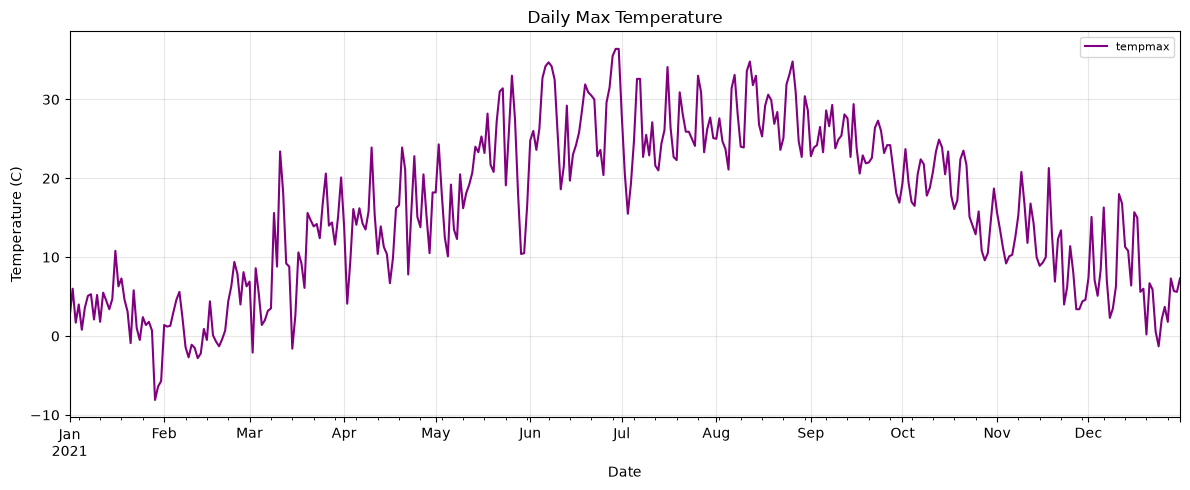

In [8]:
# Your Solution
"""Plots a line graph of tempmax using time series."""
plt.figure(figsize=(12, 5))
df_weather["tempmax"].plot(color="purple", label="tempmax")

plt.title("Daily Max Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


**Problem 7**

**Concept:** *plotting, line graphs (time series)*


**Task:**

Using `df_weather`:
* Plot the `precip` column
* Add a title
* Display the plot


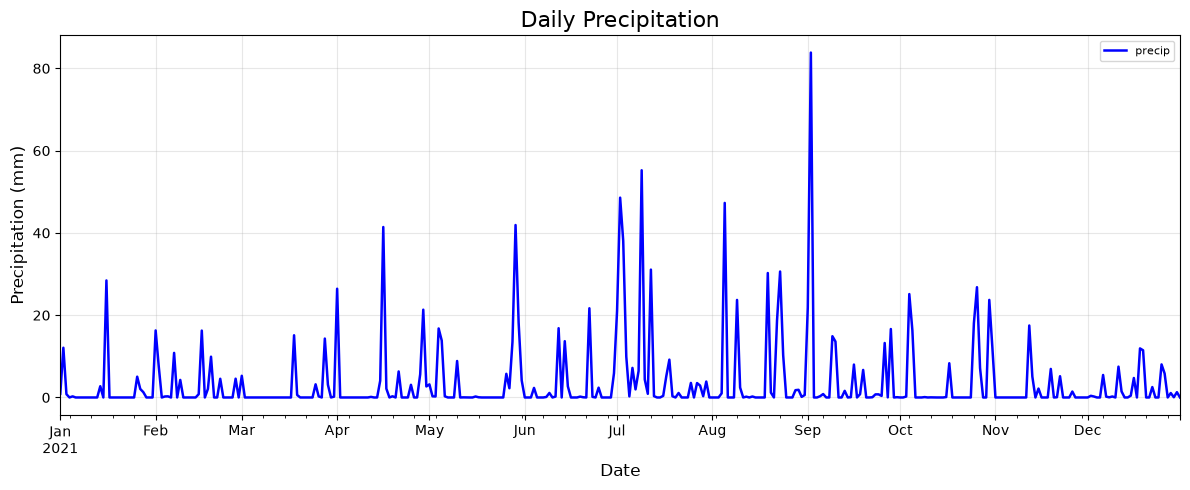

In [ ]:
# Your Solution
"""Plots a line graph of precip using time series"""
plt.figure(figsize=(12, 5))
df_weather["precip"].plot(color="blue", label="precip")

plt.title("Daily Precipitation")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


**Problem 8**

**Concept:** *histogram*


**Task:**

Using `df_weather`:
* Create a histogram of the `feelslike` column
* Use 25 bins
* Add a title
* Display the plot


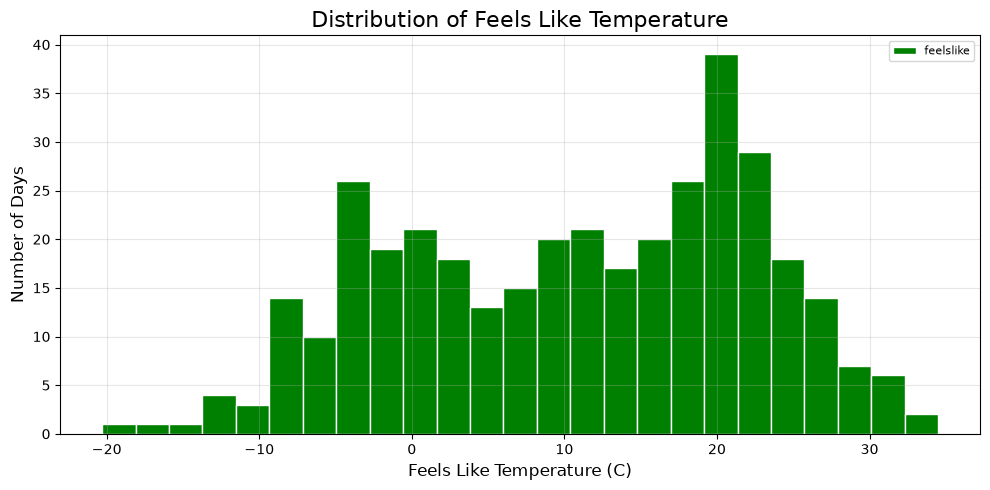

In [ ]:
# Your Solution
"""Plots a histogram of feelslike."""
plt.figure(figsize=(10, 5))
plt.hist(df_weather["feelslike"], bins=25, color="green", edgecolor="white", label="feelslike")

plt.title("Distribution of Feels Like Temperature")
plt.xlabel("Feels Like Temperature (C)")
plt.ylabel("Number of Days")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


**Problem 9**

**Concept:** *pie chart*


**Task:**

* Print value counts of `df_weather['conditions']`
* Create a pie chart of the values
* Make sure to include labels
* Print value counts of `df_econ_data['PresidentParty']`
* Create a pie chart of the values
* Make sure to include labels

**Sample Output:**

If one of your columns contained the following values:
```
blue, black, red, green, white
```
The following could be your printed value counts:
```
blue     1
black    1
red      1
green    1
white    1
Name: color, dtype: int64
```
If another column contained the following values:
```
summer, winter, summer, spring, winter
```
The following could be your printed value counts:
```
summer    2
winter    2
spring    1
Name: season, dtype: int64
```

conditions
Partially cloudy                181
Rain, Partially cloudy           89
Rain, Overcast                   47
Snow, Rain, Overcast             18
Clear                            12
Overcast                          9
Snow, Rain, Partially cloudy      7
Snow, Overcast                    1
Snow, Partially cloudy            1
Name: count, dtype: int64


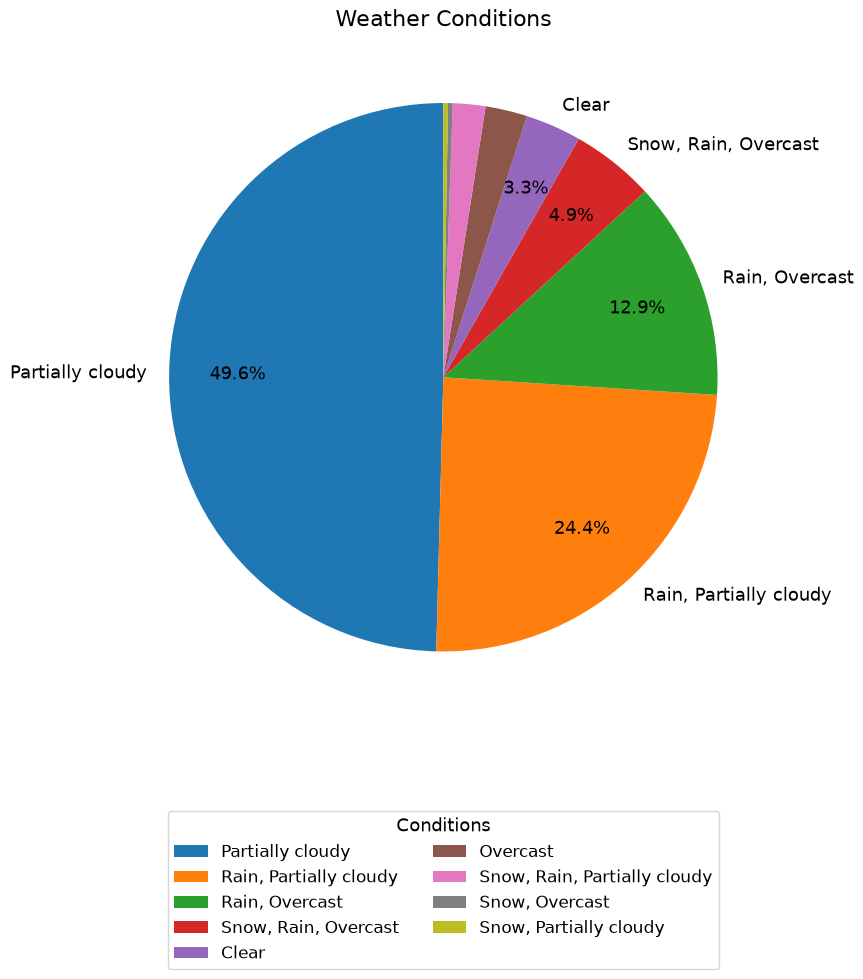

PresidentParty
Democrat      52
Republican    44
Name: count, dtype: int64


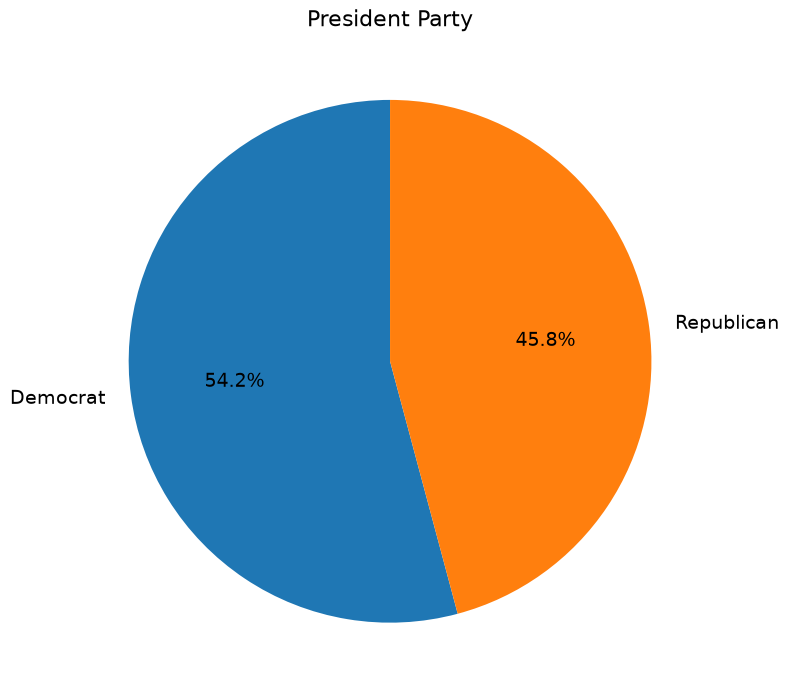

In [ ]:
# Your Solution
"""Plots pie charts of conditions and president party."""
# conditions chart
conditions_counts = df_weather["conditions"].value_counts()
print(conditions_counts)

total = conditions_counts.sum()
pie_labels = [name if count / total >= 0.03 else "" for name, count in conditions_counts.items()]
pie_pct = lambda p: f"{p:.1f}%" if p >= 3 else ""

plt.figure(figsize=(12, 10))
plt.pie(conditions_counts, labels=pie_labels, autopct=pie_pct, startangle=90,
        pctdistance=0.75, labeldistance=1.08, textprops={"fontsize": 13})
plt.title("Weather Conditions", fontsize=16)
plt.legend(conditions_counts.index, title="Conditions", loc="upper center",
           bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=12, title_fontsize=13)
plt.show()

# president party chart
party_counts = df_econ_data["PresidentParty"].value_counts()
print(party_counts)

plt.figure(figsize=(8, 8))
plt.pie(party_counts, labels=party_counts.index, autopct="%1.1f%%", startangle=90,
        textprops={"fontsize": 14})
plt.title("President Party", fontsize=16)
plt.tight_layout()
plt.show()


**Problem 10**

**Concept:** *creating new column data, extracting columns, plotting*


**Task:**

Using `df_weather`:
* Write a helper function to extract time (in hours) from a datetime string and convert it to decimal hours (float)
* Convert time using:

    `hours + (minutes / 60) + (seconds / 3600)`
* Create a new DataFrame with the same index as `df_weather`
* Add the following columns:
  * `sunrise` (converted to float)
  * `sunset` (converted to float)
  * `tempmin` (copied directly from `df_weather`)
* Plot all columns together using `.plot()`


**Sample Output:**

This is similar to how your new dataframe should look before plotting:

```
   start_time  end_time  price
P1       8.25     17.50     20
P2       8.50     17.75     35
P3       9.00     18.00     15
P4       9.25     18.25     60
P5       9.50     18.50     50
```

             sunrise     sunset  tempmin
datetime                                
2021-01-01  7.229167  16.380000     -2.4
2021-01-02  7.230000  16.394722      0.1
2021-01-03  7.230278  16.410000     -1.4
2021-01-04  7.229722  16.425833     -0.6
2021-01-05  7.228611  16.441944     -1.0


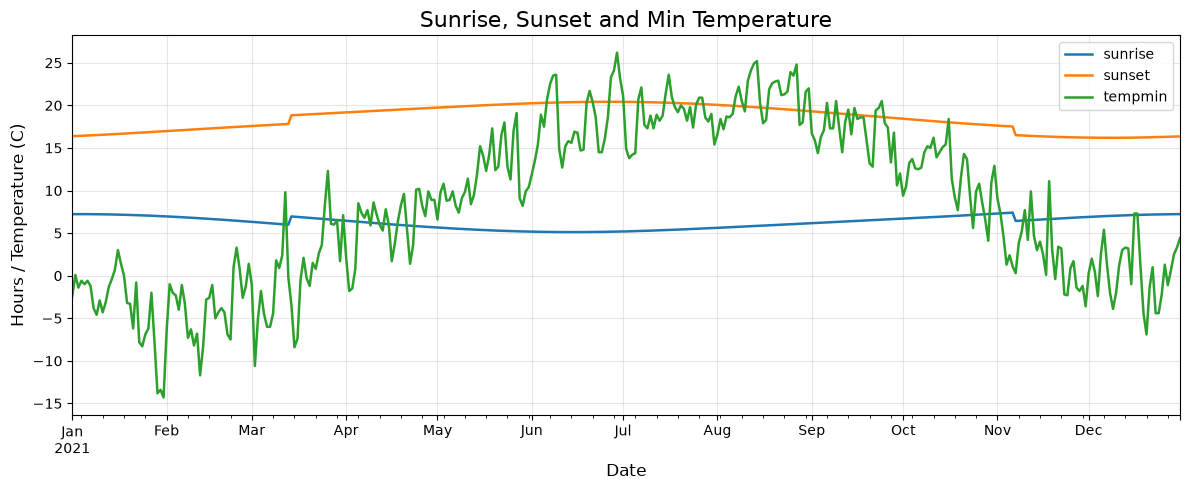

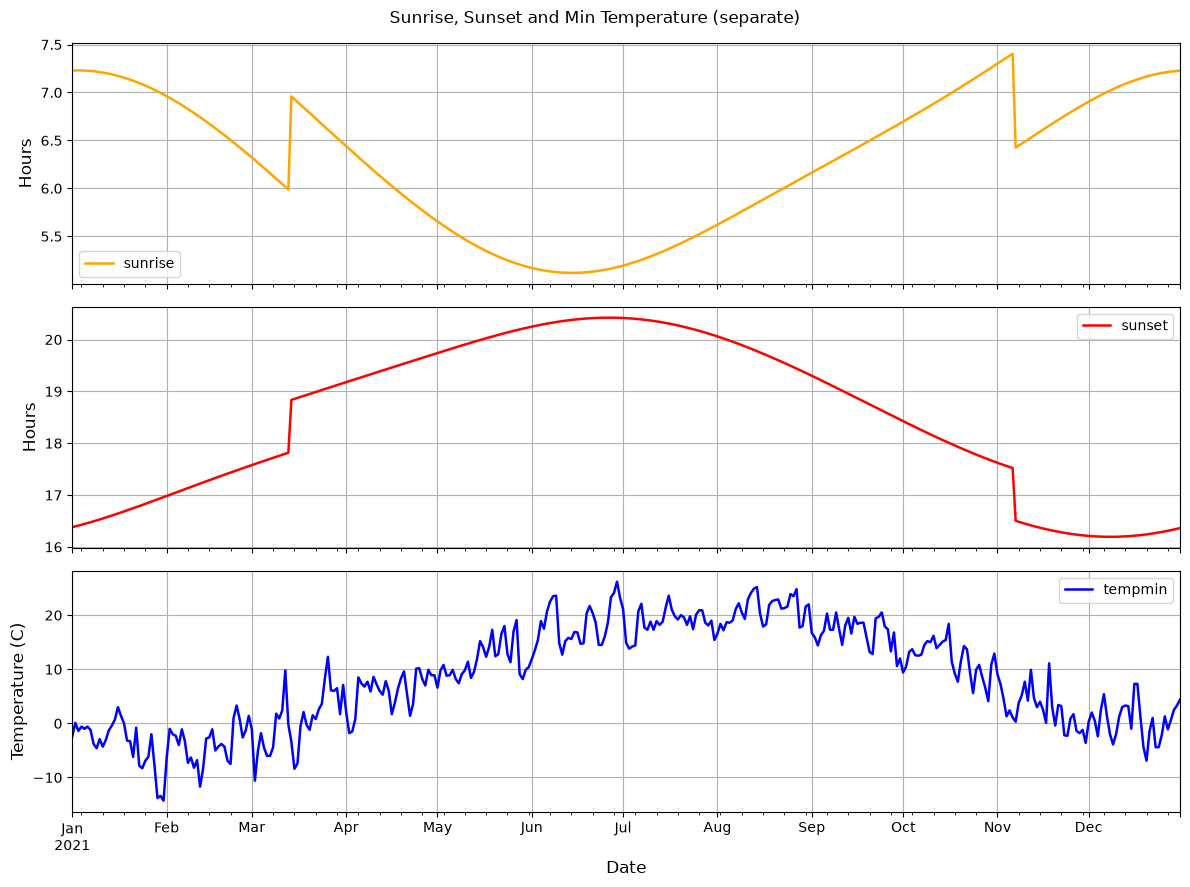

In [ ]:
# Your Solution
def time_to_decimal_hours(datetime_string):
    """Converts time to decimal hours from weather csv."""
    # time part take the time part after "T"
    time_part = datetime_string.split("T")[1]
    hours, minutes, seconds = time_part.split(":")
    return int(hours) + (int(minutes) / 60) + (int(seconds) / 3600)

"""Plots sunrise, sunset, and tempmin."""
# new DataFrame with the same index as df_weather
df_sun = pd.DataFrame(index=df_weather.index)
df_sun["sunrise"] = df_weather["sunrise"].apply(time_to_decimal_hours)
df_sun["sunset"] = df_weather["sunset"].apply(time_to_decimal_hours)
df_sun["tempmin"] = df_weather["tempmin"]

print(df_sun.head())

# plot 1: all columns together to compare
df_sun.plot(figsize=(12, 5), title="Sunrise, Sunset and Min Temperature")
plt.xlabel("Date")
plt.ylabel("Hours / Temperature (C)")
plt.grid(True, alpha=0.3)
plt.show()

# plot 2: each column in its own subplot, stacked on top of each other
axes = df_sun.plot(subplots=True, sharex=True, figsize=(12, 9), grid=True,
                   color=["orange", "red", "blue"], title="Sunrise, Sunset and Min Temperature (separate)")
axes[0].set_ylabel("Hours")
axes[1].set_ylabel("Hours")
axes[2].set_ylabel("Temperature (C)")
axes[2].set_xlabel("Date")
plt.tight_layout()
plt.show()


**Problem 11**

**Concept:** *descriptive statistics*


**Task:**


Using `df_stock_prices`:
* Print the first 5 rows
* Display descriptive statistics

**Important:**

Store your results in the variables below and print them. The autograder will check for these variables.
* `df_stock_prices_head`
* `df_stock_prices_descriptive_statistics`

**Sample Output:**


If the following was your dataframe:
```
   day  units_sold  revenue
1  Mon          10      200
2  Tue          15      300
3  Wed          12      240
4  Thu          18      360
5  Fri          20      400
```
The following will be your output:
```
SHOW FIRST 5 ROWS:
   day  units_sold  revenue
1  Mon          10      200
2  Tue          15      300
3  Wed          12      240
4  Thu          18      360
5  Fri          20      400

DESCRIPTIVE STATISTICS:
       units_sold     revenue
count    5.000000    5.000000
mean    15.000000  300.000000
std      4.123106   82.462113
min     10.000000  200.000000
25%     12.000000  240.000000
50%     15.000000  300.000000
75%     18.000000  360.000000
max     20.000000  400.000000
```

In [ ]:
# Your Solution
"""Prints the first 5 rows and descriptive statistics."""
df_stock_prices_head = df_stock_prices.head(5)
df_stock_prices_descriptive_statistics = df_stock_prices.describe()

# print floats with up to 2 decimals (the variables keep full precision)
two_decimals = lambda x: f"{x:.2f}"

print("SHOW FIRST 5 ROWS:")
print(df_stock_prices_head.to_string(float_format=two_decimals))
print()
print("DESCRIPTIVE STATISTICS:")
print(df_stock_prices_descriptive_statistics.to_string(float_format=two_decimals))


SHOW FIRST 5 ROWS:
                    formatted_date        date   high    low   open  close    volume  adjclose
date                                                                                          
2025-01-02 14:30:00     2025-01-02  1735828200 591.13 580.50 589.39 584.64  50204000    577.85
2025-01-03 14:30:00     2025-01-03  1735914600 592.60 586.43 587.53 591.95  37888500    585.08
2025-01-06 14:30:00     2025-01-06  1736173800 599.70 593.60 596.27 595.36  47679400    588.45
2025-01-07 14:30:00     2025-01-07  1736260200 597.75 586.78 597.42 588.63  60393100    581.80
2025-01-08 14:30:00     2025-01-08  1736346600 590.58 585.20 588.70 589.49  47304700    582.65

DESCRIPTIVE STATISTICS:
               date   high    low   open  close       volume  adjclose
count        250.00 250.00 250.00 250.00 250.00       250.00    250.00
mean  1751599699.20 623.14 616.07 619.79 619.96  72445004.00    615.88
std      9049658.27  45.09  47.51  46.52  46.17  29133705.67     47.58
min   1

**Problem 12**

**Concept:** *line graph (time series)*


**Task:**

Using `df_stock_prices`:
* Plot the `adjclose` column
* Add a title
* Display the plot


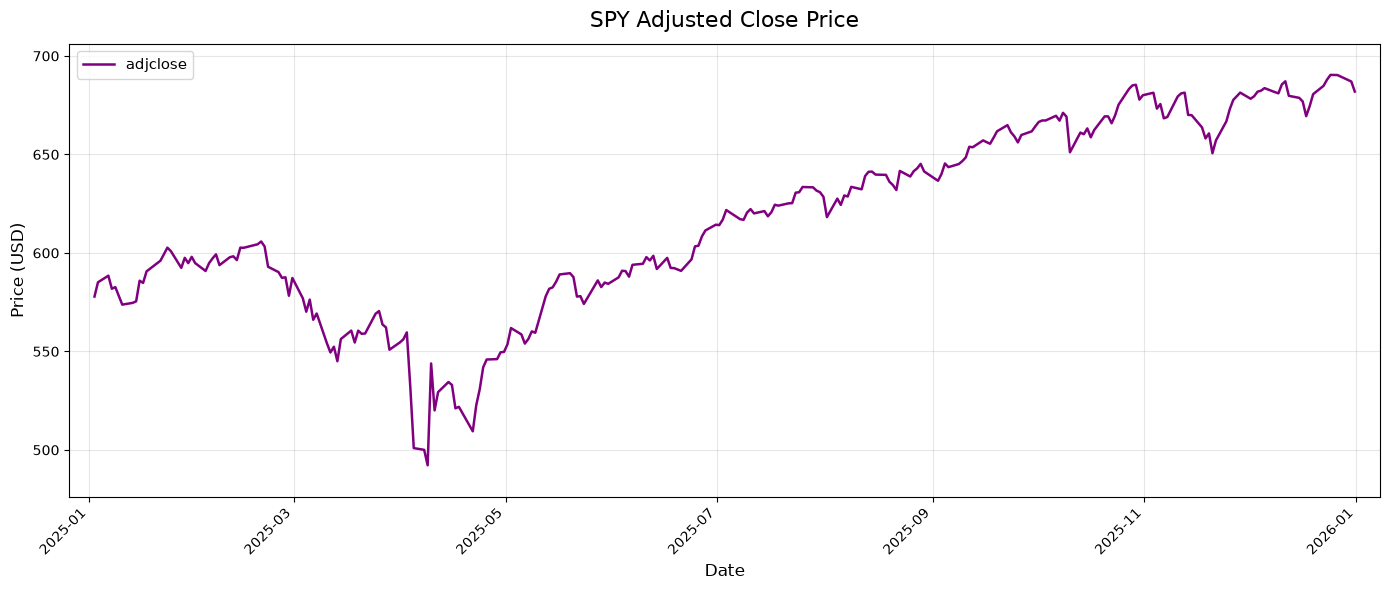

In [ ]:
# Your Solution
"""Plots a line graph of adjclose."""
plt.figure(figsize=(14, 6))
df_stock_prices["adjclose"].plot(color="purple", linewidth=1.8, label="adjclose")

plt.title("SPY Adjusted Close Price", fontsize=16, pad=12)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price (USD)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", fontsize=11)
plt.xticks(rotation=45)
plt.margins(x=0.02, y=0.08)
plt.tight_layout()
plt.show()


**Problem 13**

**Concept:** *histogram*


**Task:**

Using `df_stock_prices`:
* Create a histogram of `adjclose`
* Use 25 bins
* Add a title
* Display the plot


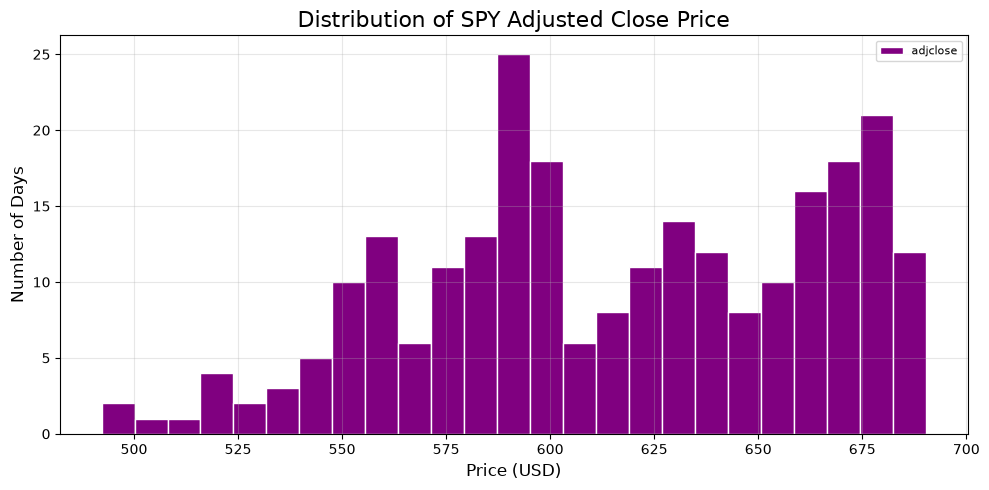

In [ ]:
# Your Solution
"""Plots a histogram of adjclose."""
plt.figure(figsize=(10, 5))
plt.hist(df_stock_prices["adjclose"], bins=25, color="purple", edgecolor="white", label="adjclose")

plt.title("Distribution of SPY Adjusted Close Price")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Days")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


**Problem 14**

**Concept:** *Creating new column.*


**Task:**

Write a function `add_range_column(df, col_a, col_b)` that:
* Creates a new column `"range"` equal to `col_a - col_b`
* Returns the updated DataFrame

**Sample Output:**

If the following was your dataframe before adding the new column:
```
   price  discount
P1     20         2
P2     35         5
P3     15         1
P4     60        10
P5     50         8
```
The following will be your output after creating the `"range"` column:
```
   price  discount  range
P1     20         2     18
P2     35         5     30
P3     15         1     14
P4     60        10     50
P5     50         8     42
```

In [ ]:
# Your Solution
# bigger, spread-out plots for the test cell below (full graph stays visible)
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.autolayout"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["lines.linewidth"] = 1.8

def add_range_column(df, col_a, col_b):
    """Adds a range column to a DataFrame."""
    result = df.copy()
    result["range"] = result[col_a] - result[col_b]
    return result

# sample output: dataframe after creating the "range" column
df_example = pd.DataFrame({"price": [20, 35, 15, 60, 50], "discount": [2, 5, 1, 10, 8]},
                          index=["P1", "P2", "P3", "P4", "P5"])
print(add_range_column(df_example, "price", "discount"))


    price  discount  range
P1     20         2     18
P2     35         5     30
P3     15         1     14
P4     60        10     50
P5     50         8     42


Test cases for problem 14

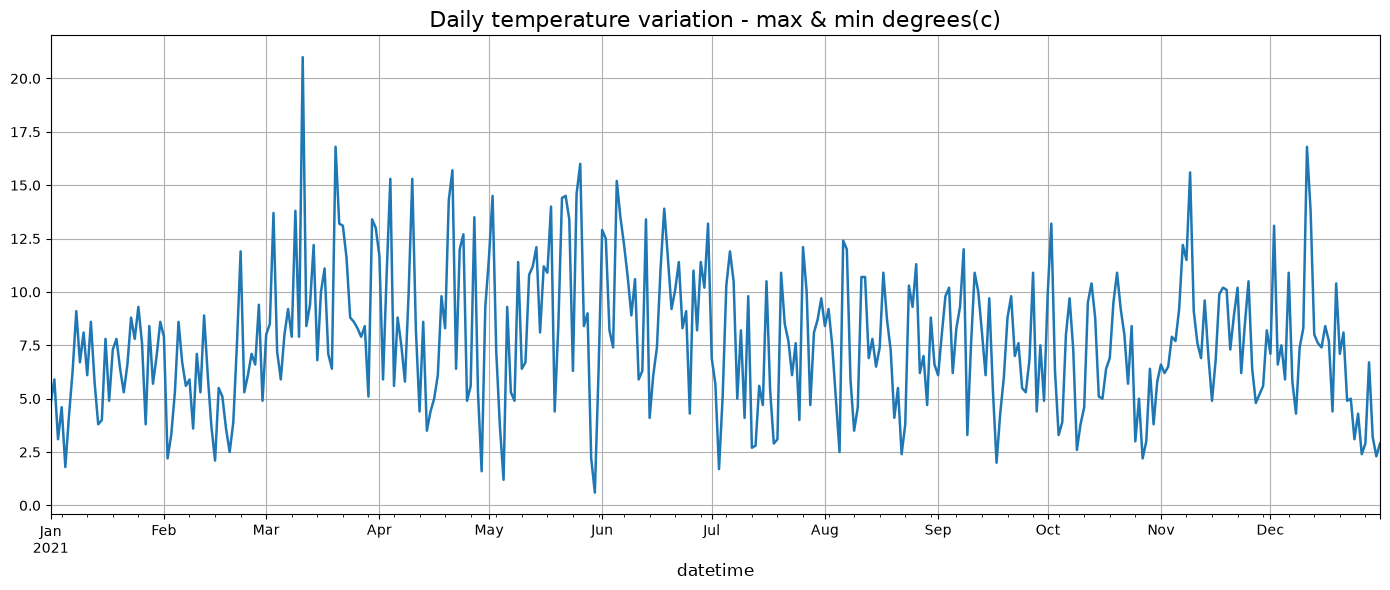

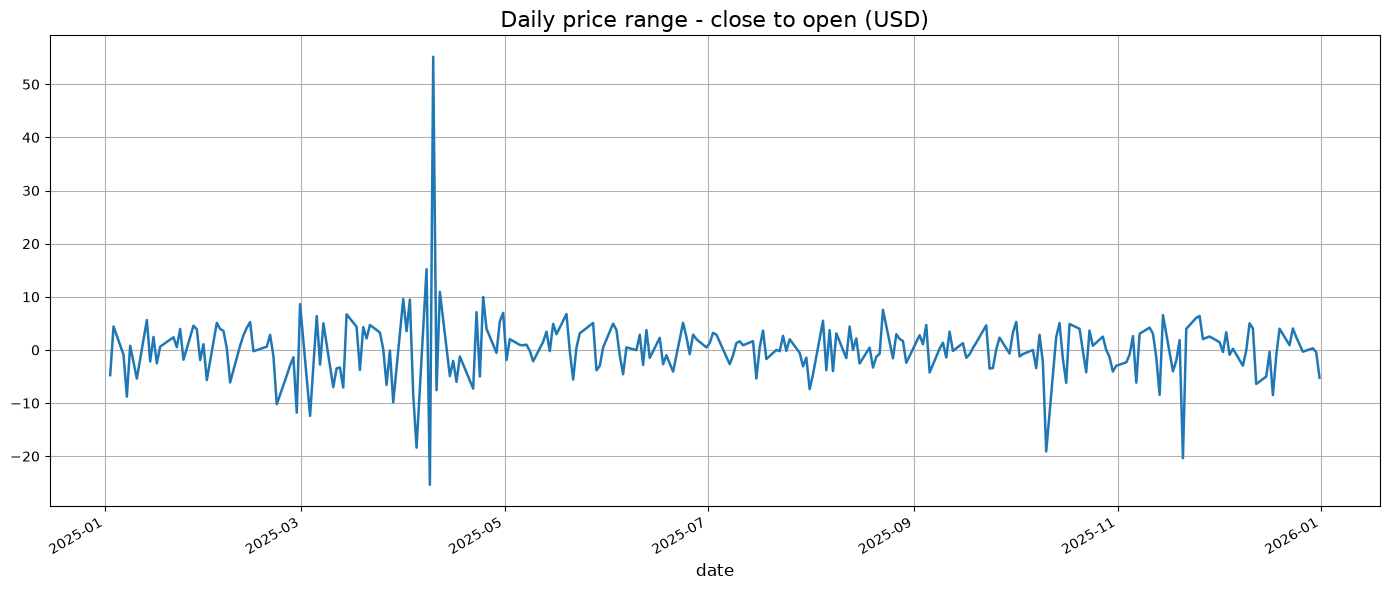

In [ ]:
# test cases
df_result = add_range_column(df_weather, "tempmax", "tempmin")
df_result['range'].plot(title="Daily temperature variation - max & min degrees(c)")
plt.show()

df_result = add_range_column(df_stock_prices, "close", "open")
df_result['range'].plot(title="Daily price range - close to open (USD)")
plt.show()




**Problem 15**

**Concept:** *Filtering `DataFrame` with boolean conditions*


**Task:**


Write a function `filter_rows_matching_pattern(df, column, pattern)` that:
* Returns rows where the specified column contains the given pattern
* Handles missing values
* Prints the number of matching rows

**Sample Output:**

If your selected column contained matching text values, the following could be your output:
```
Found 1 records of color containing blue.
Found 1 records of product containing hat.
Found 1 records of color containing red.
```

In [ ]:
# Your Solution
def filter_rows_matching_pattern(df, column, pattern):
    """Returns rows where a column contains a pattern for DataFrame."""
    # na=False treats missing values as no match
    matches = df[column].str.contains(pattern, na=False, regex=False)
    result = df[matches]
    print(f"Found {len(result)} records of {column} containing {pattern}.")
    return result


Test cases for problem 15

In [ ]:
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Snow")
# print(df_result.head())
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Overcast")
df_result = filter_rows_matching_pattern(df_weather, "conditions", "Clear")
# print(df_result.head())


Found 27 records of conditions containing Snow.
Found 75 records of conditions containing Overcast.
Found 12 records of conditions containing Clear.


**Problem 16**

**Concept:** *Creating new DataFrame with categorical data.*


**Task:**

Write a function `create_df_categorical(df_source, column_name)` that:
* Creates a new DataFrame with:
  * counts of each category
  * percentage of each category
* Returns the new DataFrame

**Sample Output:**

If the following was one of your categorical columns:
```
blue, black, red, green, white
```
The following will be your output:
```
       count  pct
blue       1  0.2
black      1  0.2
red        1  0.2
green      1  0.2
white      1  0.2
```
If another categorical column contained:
```
summer, winter, summer, spring, winter
```
The following will be your output:
```
        count  pct
summer      2  0.4
winter      2  0.4
spring      1  0.2
```

In [ ]:
# Your Solution
def create_df_categorical(df_source, column_name):
    """Returns the count and percentage of each category."""
    # count of each category, most common first
    counts = df_source[column_name].value_counts()
    # percentage of each category as a fraction of all counted rows (0.2 = 20%)
    percents = counts / counts.sum()
    return pd.DataFrame({"count": counts, "pct": percents})


Test cases for problem 16

In [ ]:
# test cases:
# 1: show categories of conditions
df_result = create_df_categorical(df_weather, "conditions")
print("CONDITIONS:")
print(df_result)
# 2: show categories of description
df_result = create_df_categorical(df_weather, "description")
print("DESCRIPTION:")
print(df_result)
# 3: show categories of UV index
df_result = create_df_categorical(df_weather, "uvindex")
print("UV INDEX")
print(df_result)

NameError: name 'df_weather' is not defined

**Problem 17**

**Concept:** *Filtering records by category.*


**Task:**

Write a function `filter_weather(df, conditions, temp_min, temp_max)` that:
* Filters rows where:
  * conditions contain the given string
  * `tempmax` ≤ `temp_max`
  * `tempmin` ≥ `temp_min`
* Prints intermediate counts
* Returns the filtered DataFrame

**Sample Output:**

If your data matched the filtering conditions step by step, the following could be your output:
```
4 records with conditions Blue
3 records with conditions Blue and tempmax <= 50
2 records with conditions Blue and 20 <= temp <= 50
Found 2 records with conditions of Blue and temp between 20 and 50.
```

In [ ]:
# Your Solution
def filter_weather(df, conditions, temp_min, temp_max):
    """Returns weather rows filtered by conditions and temperature using DataFrame."""
    # step 1: conditions contain the given string
    result = df[df["conditions"].str.contains(conditions, na=False, regex=False)]
    print(f"{len(result)} records with conditions {conditions}")

    # step 2: tempmax <= temp_max
    result = result[result["tempmax"] <= temp_max]
    print(f"{len(result)} records with conditions {conditions} and tempmax <= {temp_max}")

    # step 3: tempmin >= temp_min
    result = result[result["tempmin"] >= temp_min]
    print(f"{len(result)} records with conditions {conditions} and {temp_min} <= temp <= {temp_max}")

    print(f"Found {len(result)} records with conditions of {conditions} and temp between {temp_min} and {temp_max}.")
    return result


Test cases for problem 17

In [ ]:
# looking for perfect running days:
df_result = filter_weather(df_weather, "Partially cloudy", 4, 15)
print(f"The best running days were:")
print(df_result[['tempmin', 'tempmax','conditions',]])
print()

# looking for perfect beach days:
df_result = filter_weather(df_weather, "Clear", 5, 30)
print(f"The best beach days were:")
print(df_result[['tempmin', 'tempmax','conditions',]])



278 records with conditions Partially cloudy
110 records with conditions Partially cloudy and tempmax <= 15
19 records with conditions Partially cloudy and 4 <= temp <= 15
Found 19 records with conditions of Partially cloudy and temp between 4 and 15.
The best running days were:
            tempmin  tempmax              conditions
datetime                                            
2021-03-27      6.1     14.0        Partially cloudy
2021-03-29      6.5     11.6  Rain, Partially cloudy
2021-04-05      8.5     14.1        Partially cloudy
2021-04-07      6.8     14.3        Partially cloudy
2021-04-08      7.7     13.5        Partially cloudy
2021-04-13      5.3     13.9        Partially cloudy
2021-04-14      7.8     11.3        Partially cloudy
2021-04-26      8.2     13.8        Partially cloudy
2021-05-07      8.2     13.5        Partially cloudy
2021-05-08      7.4     12.3        Partially cloudy
2021-10-24      5.6     14.0        Partially cloudy
2021-10-28      6.6      9.6   

**Problem 18**

**Concept:** *Creating DataFrame, standardizing values.*


**Task:**

Write a function `create_standardized_values(df_source, columns, row_index=None)` that:
* Creates a new DataFrame
* Standardizes values relative to a given row
* Uses the first row if none is provided
* Returns the new DataFrame

**Sample Output:**

If the following was your dataframe:
```
      high_value  low_value
2020        100        50
2021        120        55
2022        140        60
2023        160        70
2024        180        75
```
If you call the function
`create_standardized_values(df_example, ["high_value", "low_value"], 2020)`,
you should get the following as the output:
```
      high_value  low_value
2020         1.0       1.00
2021         1.2       1.10
2022         1.4       1.20
2023         1.6       1.40
2024         1.8       1.50

```

      high_value  low_value
2020         1.0        1.0
2021         1.2        1.1
2022         1.4        1.2
2023         1.6        1.4
2024         1.8        1.5


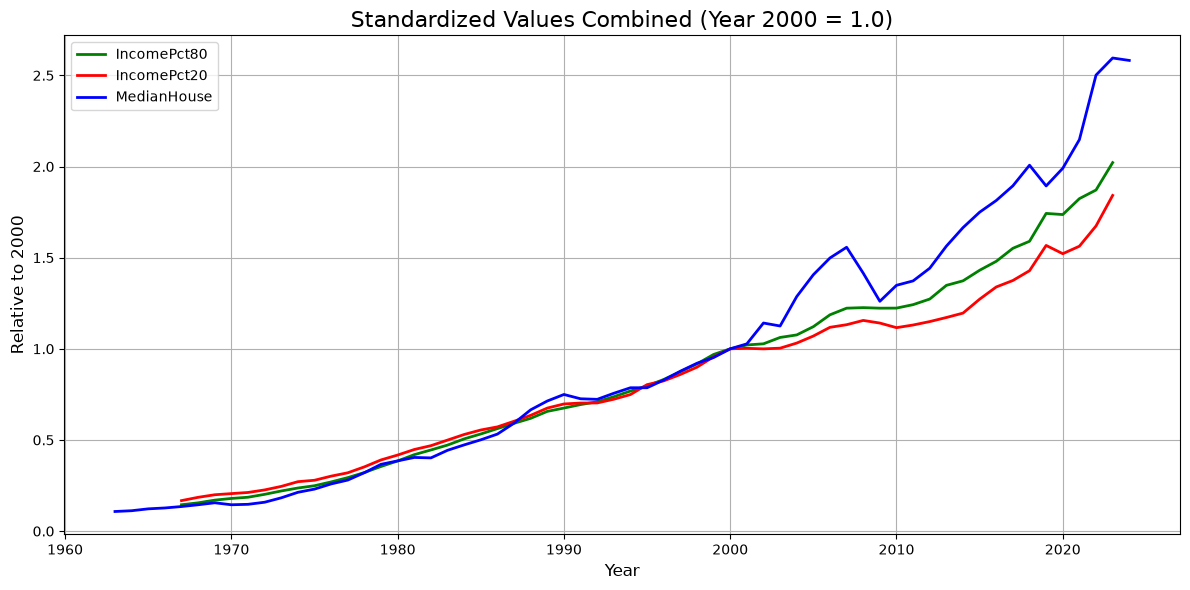

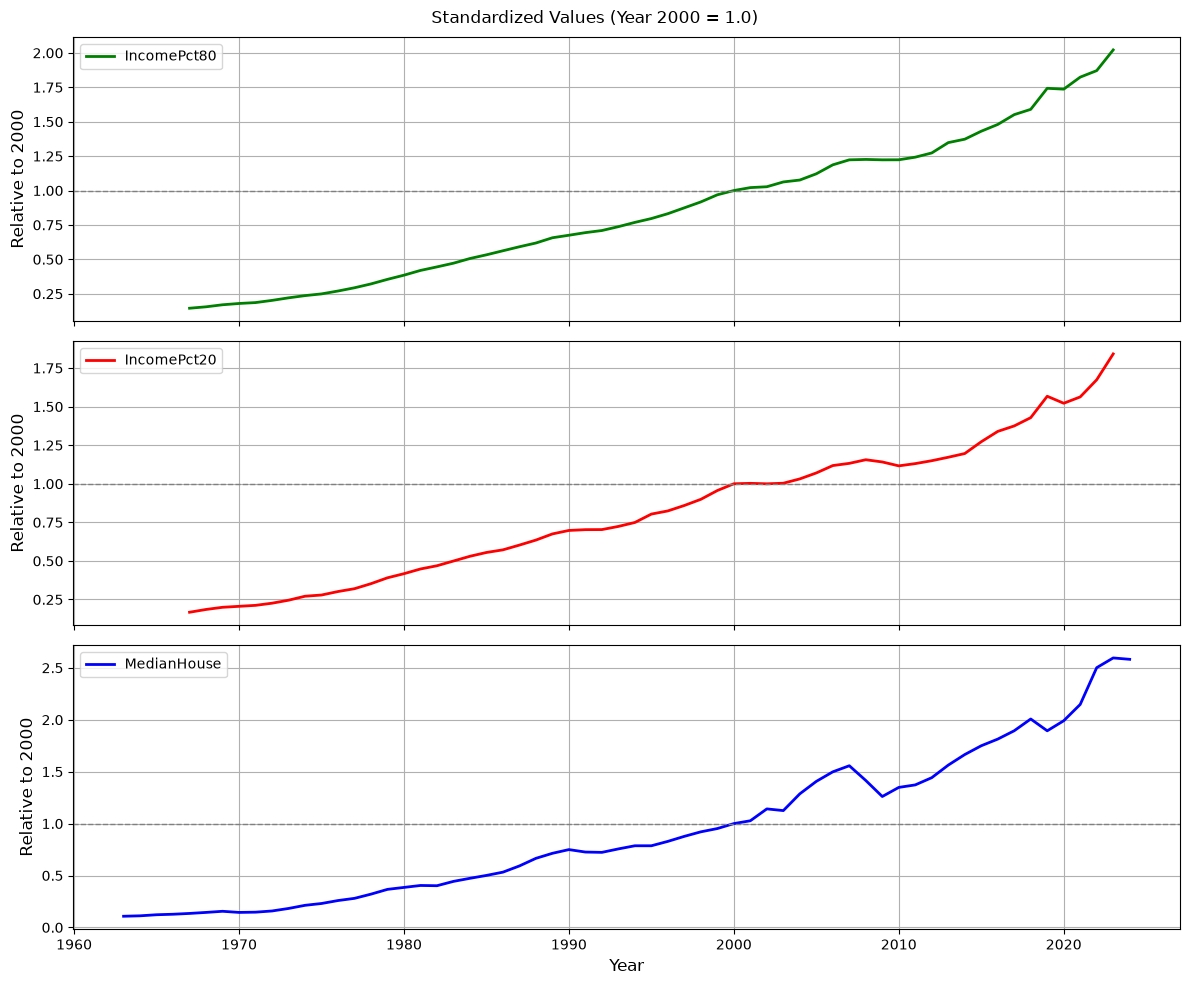

In [ ]:
# Your Solution
def create_standardized_values(df_source, columns, row_index=None):
    """Returns values standardized relative to a row using DataFrame."""
    # reference row: first row if row_index is None
    if row_index is None:
        base = df_source[columns].iloc[0]
    else:
        base = df_source.loc[row_index, columns]

    # divide every row by the reference row (reference row becomes 1.0)
    return df_source[columns] / base

# sample output: standardized relative to year 2020
df_example = pd.DataFrame({"high_value": [100, 120, 140, 160, 180], "low_value": [50, 55, 60, 70, 75]},
                          index=[2020, 2021, 2022, 2023, 2024])
print(create_standardized_values(df_example, ["high_value", "low_value"], 2020))

# combined graph: all 3 lines on one plot to compare (relative to year 2000)
df_econ_std = create_standardized_values(df_econ_data, ["IncomePct80", "IncomePct20", "MedianHouse"], 2000)
df_econ_std.plot(figsize=(12, 6), linewidth=2, grid=True, color=["green", "red", "blue"],
                 title="Standardized Values Combined (Year 2000 = 1.0)")
plt.xlabel("Year")
plt.ylabel("Relative to 2000")
plt.legend(loc="upper left", fontsize=10)
plt.show()

# clearer graph: each of the 3 lines in its own subplot (relative to year 2000)
axes = df_econ_std.plot(subplots=True, sharex=True, figsize=(12, 10), grid=True, linewidth=2,
                        color=["green", "red", "blue"], title="Standardized Values (Year 2000 = 1.0)")
for ax in axes:
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Relative to 2000")
    ax.legend(loc="upper left", fontsize=10)
axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()


Test cases for problem 18

<Axes: title={'center': 'IncomePct80, IncomePct20 and MedianHouse (Year 2000 = 1.0)'}, xlabel='Year'>

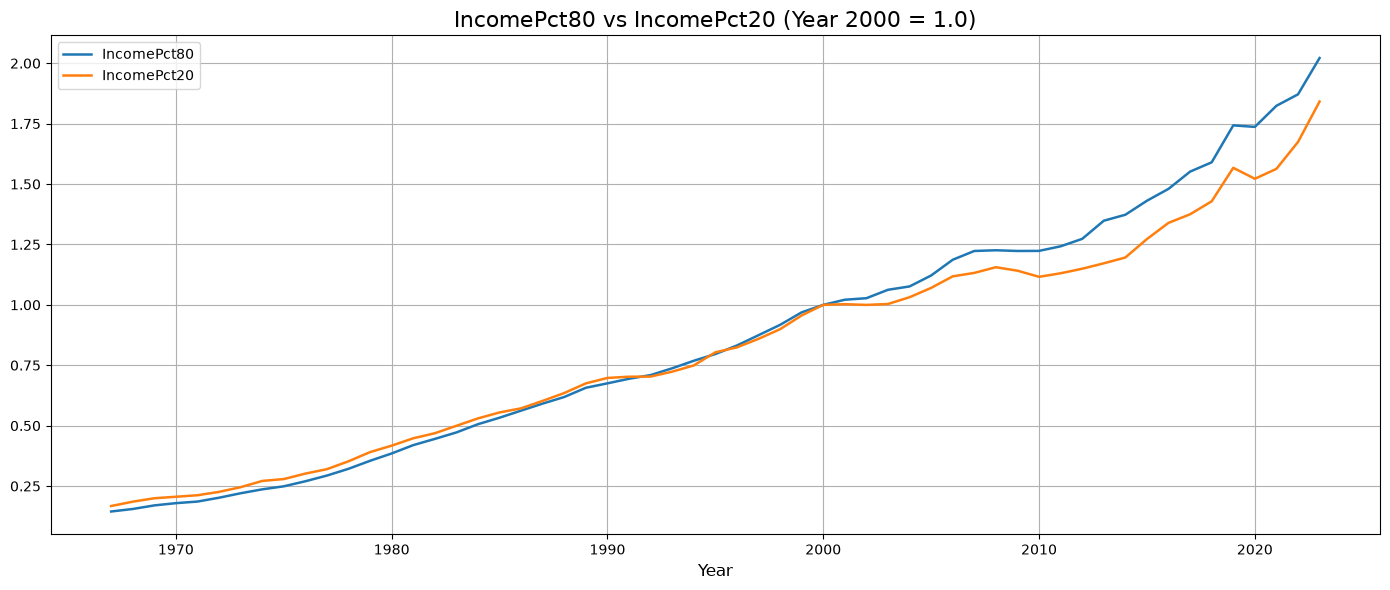

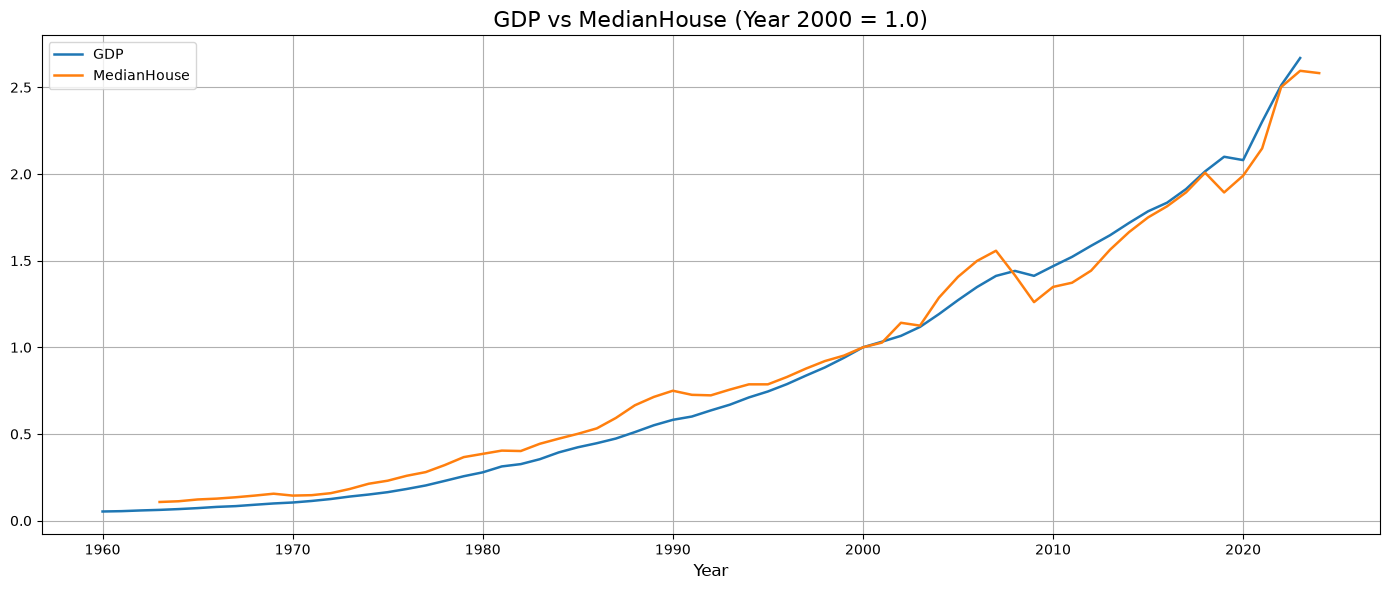

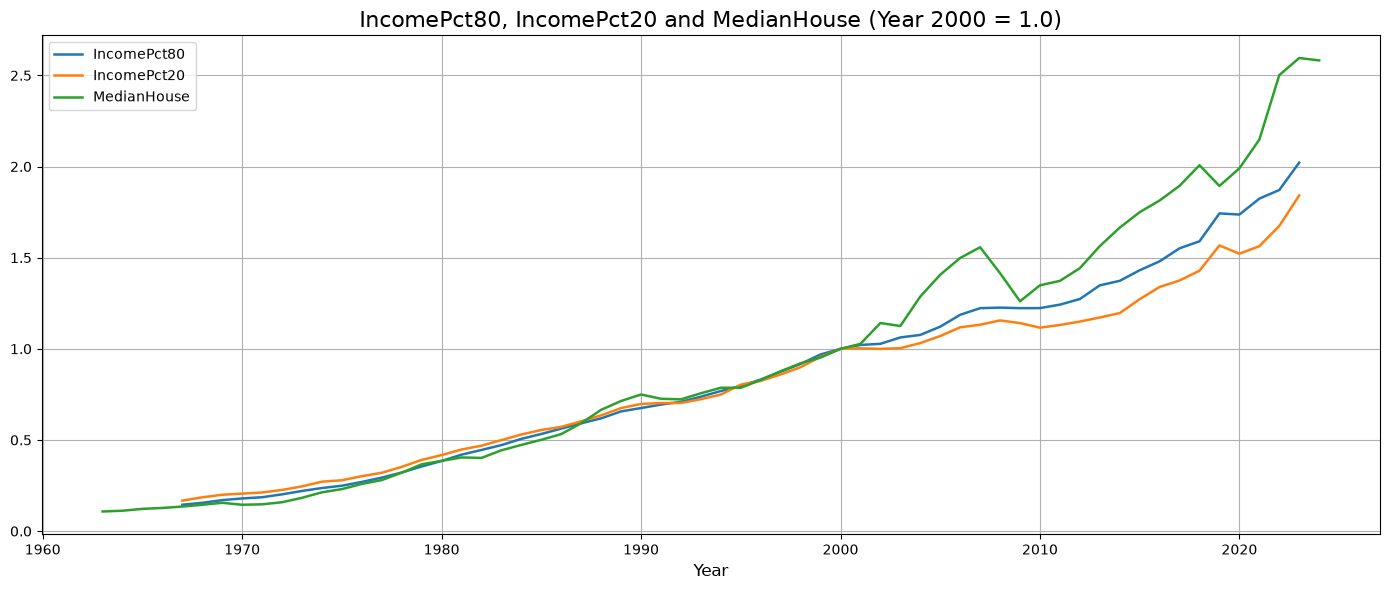

In [ ]:
# test cases

# # show open/close prices relative to first item (row_index = None)
# df_result = create_standardized_values(df_stock_prices, ["open", "close"])
# df_result.plot()

# show values relative to year 2000
df_result = create_standardized_values(df_econ_data, ["IncomePct80", "IncomePct20"], 2000)
df_result.plot(title="IncomePct80 vs IncomePct20 (Year 2000 = 1.0)")

df_result = create_standardized_values(df_econ_data, ["GDP", "MedianHouse"], 2000)
df_result.plot(title="GDP vs MedianHouse (Year 2000 = 1.0)")

df_result = create_standardized_values(df_econ_data, ["IncomePct80", "IncomePct20", "MedianHouse"], 2000)
df_result.plot(title="IncomePct80, IncomePct20 and MedianHouse (Year 2000 = 1.0)")